# Part (b): Deep Q-Network on MsPacman-v5

A Double DQN with a dueling head learns Ms. Pac-Man from the game images (preprocessed with the function given in the assignment, 4 stacked frames) with $\gamma = 0.99$ and 9 actions. Because one training run takes many hours, there is **no hyperparameter ladder**: the configuration combines the insights of part (a) (Double DQN, slow target network, Huber loss with gradient clipping, a large replay buffer) with the standard Atari DQN settings.

**Structure of this notebook**
1. Setup: constants, configuration, preprocessing
2. DQN building blocks: frame stack, replay buffer, network, learning step, checkpoints, training loop, evaluation
3. Training (resumable) with the plots (i) max Q and (ii) episode rewards
4. Model selection and evaluation: (iii) 500 greedy episodes
5. Non-standard plot: where Ms. Pac-Man goes, and her Q-values during one game
6. Edge cases
7. Validation tests (each prints `[PASS]` / `[FAIL]`)

**How to run.** Run all cells from top to bottom. Training **resumes automatically**: every 250 episodes, a full checkpoint (networks, optimizer, replay buffer, random-generator states, log) is written to `checkpoints/b/dqn/checkpoint/`. If the kernel dies, run all cells again and training continues from the last checkpoint, bit-identical to an uninterrupted run (Test 10). A finished run is only loaded. All later evaluations are cached in `checkpoints/b/dqn/cache/`, and all figures are written to `report/figures/b_*.png`.

In [ ]:
import os

os.environ.setdefault(
    "CUBLAS_WORKSPACE_CONFIG", ":4096:8"
)  # deterministic cuBLAS, needed for an exact resume

import pickle
import shutil
import time
from dataclasses import asdict, dataclass, replace
from pathlib import Path

import ale_py
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib.colors import LogNorm
from tqdm.auto import tqdm

gym.register_envs(ale_py)
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.benchmark = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(
    f"Device: {DEVICE}"
    + (f" ({torch.cuda.get_device_name()})" if DEVICE.type == "cuda" else "")
)

GAMMA = 0.99  # given by the assignment
N_ACTIONS = 9
ACTION_NAMES = (
    "NOOP",
    "UP",
    "RIGHT",
    "LEFT",
    "DOWN",
    "UPRIGHT",
    "UPLEFT",
    "DOWNRIGHT",
    "DOWNLEFT",
)
STACK = 4  # frames per state
FRAME_SHAPE = (88, 80)
PACMAN_RGB = (210, 164, 74)  # Ms. Pac-Man's colour in the raw frame
Q_BOUND = 1 / (1 - GAMMA)  # rewards are clipped to {0, 1}, so Q <= 100

WINDOW = 100  # moving average
N_EVAL = 500  # greedy roll-outs after training (assignment iii)
N_VAL = 30  # validation episodes per snapshot (model selection)
EVAL_SEED, VAL_SEED, TRAIN_SEED = (
    0,
    10_000,
    1_000_000,
)  # disjoint seed ranges: test, validation, training

FIGURES = Path("report/figures")
CHECKPOINTS = Path("checkpoints/b")
FIGURES.mkdir(parents=True, exist_ok=True)

plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.3,
    }
)
COLORS = plt.rcParams["axes.prop_cycle"].by_key()["color"]


def save_figure(fig, name: str) -> None:
    fig.savefig(FIGURES / f"b_{name}.png", dpi=150, bbox_inches="tight")

Device: cuda (NVIDIA GeForce GTX 1650 with Max-Q Design)


## 1. Setup

All hyperparameters of a run live in one `Config`. `MAIN` is the reported run; the tests use small variants of it.

| Topic | Choice | Why |
|---|---|---|
| Environment | `ALE/MsPacman-v5` with its defaults: frameskip 4, sticky actions (25 %), 9 actions | Required by the assignment |
| State | Assignment preprocessing (88×80 int8), **last 4 frames stacked** | One frame shows neither Ms. Pac-Man's nor the ghosts' direction |
| Network | Nature CNN (32@8×8/4, 64@4×4/2, 64@3×3/1) + **dueling head** (value and advantage streams of 512 units) | Standard for Atari; dueling separates "how good is this state" from "which action", useful with 9 often equivalent actions |
| Algorithm | **Double DQN**, Polyak target network ($\tau = 0.001$ per update) | Part (a): overestimation stayed small; the slow target network was essential |
| Loss | **Huber**, gradient norm clipped at 10, Adam (lr $10^{-4}$, eps $1.5 \cdot 10^{-4}$), batch 32 | Part (a): Huber + clipping made the policy stable |
| Replay buffer | **1,000,000 transitions**, stored as single frames (≈ 7 GB RAM) | Part (a): a large buffer prevents forgetting |
| Updates | 50,000 random transitions first, then one gradient step every 4 agent steps | Standard Atari setting |
| Rewards | Learning reward **clipped to $\text{sign}(r) \in \{0, 1\}$**; all plots show the raw game score | Dots (10) and ghosts (up to 1,600) differ by 160×; clipping keeps Q bounded by $1/(1-\gamma) = 100$ |
| Life loss | **Terminal for the TD target** (no bootstrap), but the game goes on; one episode = one game (3 lives) | Losing a life gives a learning signal, the episode stays what the assignment counts |
| Exploration | $\epsilon$ per agent step: 1.0 → 0.1 over the first 1M steps, → 0.01 at 3M steps; evaluation greedy | Episode lengths vary a lot, so the schedule follows the steps, not the episodes |
| Length | **6,000 episodes** | Top of the assignment's 4,000–6,000 |

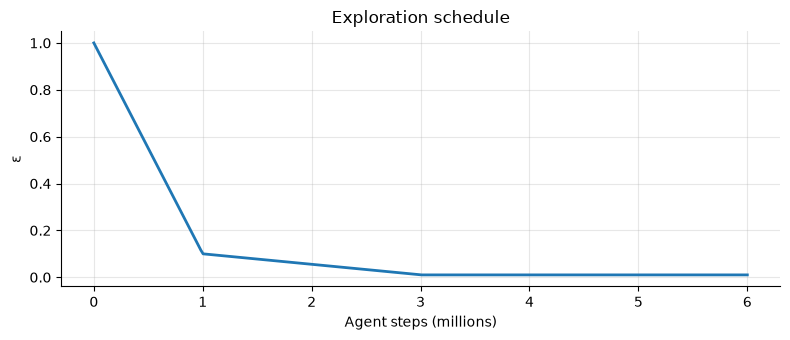

In [ ]:
@dataclass(frozen=True)
class Config:
    name: str = "dqn"  # folder in checkpoints/b/
    episodes: int = 6_000
    gamma: float = GAMMA
    buffer_size: int = 1_000_000
    batch_size: int = 32
    learning_starts: int = 50_000  # random transitions before the first update
    train_every: int = 4  # agent steps per gradient step
    lr: float = 1e-4
    adam_eps: float = 1.5e-4
    tau: float = 0.001  # Polyak factor of the target network per update
    grad_clip: float = 10.0
    eps_steps: tuple = (
        0,
        1_000_000,
        3_000_000,
    )  # epsilon is linear between these agent steps ...
    eps_values: tuple = (1.0, 0.1, 0.01)  # ... and these values
    checkpoint_every: int = (
        250  # episodes between full checkpoints (incl. replay buffer)
    )
    snapshot_every: int = 500  # episodes between saved weights (model selection, tests)
    max_episode_steps: int | None = None  # None: the v5 limit of 108,000 frames
    seed: int = 0


MAIN = Config()
RUN_DIR = CHECKPOINTS / MAIN.name


def epsilon(config: Config, step: int) -> float:
    return float(np.interp(step, config.eps_steps, config.eps_values))


fig, ax = plt.subplots(figsize=(8, 3.5))
steps = np.linspace(0, 6e6, 300)
ax.plot(steps / 1e6, [epsilon(MAIN, s) for s in steps], color=COLORS[0], lw=2)
ax.set(title="Exploration schedule", xlabel="Agent steps (millions)", ylabel="ε")
fig.tight_layout()
save_figure(fig, "epsilon_schedule")
plt.show()

**Preprocessing.** `preprocess_observation` is the function from the assignment: crop and downsize to 88×80, sum the colour channels to greyscale, set Ms. Pac-Man's colour to 0 (contrast) and map to int8. The network gets the int8 frames divided by 128, i.e. values in $[-1, 1)$.

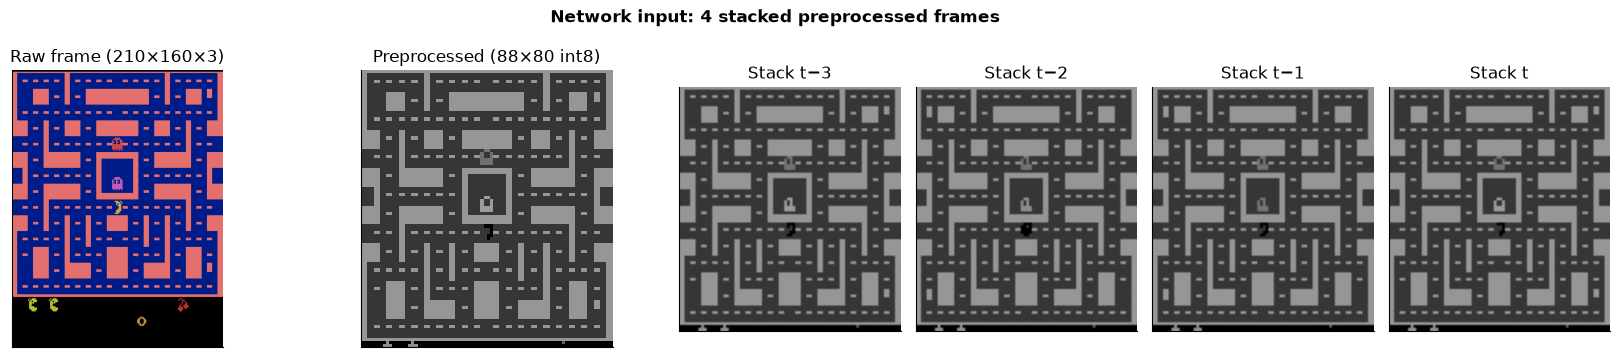

In [ ]:
MSPACMAN_COLOR = 210 + 164 + 74


def preprocess_observation(obs):
    img = obs[1:176:2, ::2]  # crop and downsize
    img = img.sum(axis=2)  # to greyscale
    img[img == MSPACMAN_COLOR] = 0  # improve contrast
    img = (img // 3 - 128).astype(np.int8)  # normalize from -128 to 127
    return img.reshape(88, 80, 1)


def preprocess(obs) -> np.ndarray:
    """(88, 80) int8 frame."""
    return preprocess_observation(obs)[..., 0]


def make_env(
    config: Config | None = None, sticky: bool = True, render_mode=None
) -> gym.Env:
    kwargs = {"repeat_action_probability": 0.25 if sticky else 0.0}
    if config is not None and config.max_episode_steps is not None:
        kwargs["max_episode_steps"] = config.max_episode_steps
    env = gym.make("ALE/MsPacman-v5", render_mode=render_mode, **kwargs)
    assert env.action_space.n == N_ACTIONS, env.action_space
    return env


def env_step(env: gym.Env, action: int, lives: int):
    """One agent step (4 frames). Returns obs, raw reward, terminated, truncated, lives, life_lost."""
    obs, reward, terminated, truncated, info = env.step(action)
    return obs, reward, terminated, truncated, info["lives"], info["lives"] < lives


def pacman_position(obs) -> tuple[float, float] | None:
    """Centre (row, column) of Ms. Pac-Man in the raw frame, None if she is not visible."""
    mask = (obs == PACMAN_RGB).all(axis=2)
    if not mask.any():
        return None
    rows, cols = np.nonzero(mask)
    return rows.mean(), cols.mean()


env = make_env()
obs, info = env.reset(seed=EVAL_SEED)
frames = [preprocess(obs)]
for _ in range(STACK - 1):
    obs, *_ = env.step(3)  # LEFT
    frames.append(preprocess(obs))
env.close()

fig, axes = plt.subplots(
    1,
    2 + STACK,
    figsize=(17, 3.6),
    gridspec_kw={"width_ratios": [1.6, 1.6] + [1] * STACK},
)
axes[0].imshow(obs)
axes[0].set_title("Raw frame (210×160×3)")
axes[1].imshow(frames[-1], cmap="gray", vmin=-128, vmax=127)
axes[1].set_title("Preprocessed (88×80 int8)")
for k, (ax, frame) in enumerate(zip(axes[2:], frames)):
    ax.imshow(frame, cmap="gray", vmin=-128, vmax=127)
    ax.set_title(f"Stack t−{STACK - 1 - k}" if k < STACK - 1 else "Stack t")
for ax in axes:
    ax.set(xticks=[], yticks=[])
    ax.grid(False)
fig.suptitle("Network input: 4 stacked preprocessed frames", fontweight="bold")
fig.tight_layout()
save_figure(fig, "preprocessing")
plt.show()

## 2. DQN Building Blocks

**Frame stack and replay buffer.** The agent sees the last 4 frames. At the start of a game, the stack is filled with the first frame. The replay buffer stores every frame only **once** (with action, clipped reward, TD-terminal flag, end-of-game flag and start-of-game flag) and builds the stacks of $s$ and $s'$ from neighbouring indices when sampling. That needs a quarter of the memory of storing stacks. A stack never reaches back across the start of a game; instead it repeats the game's first frame, exactly like the online stack. Indices are logical (counting all frames ever added) and wrap around the array.

In [ ]:
class FrameStack:
    def __init__(self) -> None:
        self.frames = np.zeros((STACK, *FRAME_SHAPE), dtype=np.int8)

    def reset(self, frame: np.ndarray) -> np.ndarray:
        self.frames[:] = frame
        return self.frames

    def push(self, frame: np.ndarray) -> np.ndarray:
        self.frames[:-1] = self.frames[1:]
        self.frames[-1] = frame
        return self.frames


class ReplayBuffer:
    """Ring buffer of single frames. Index t holds frame o_t and the step taken from it: a_t, r_t (clipped),
    terminal_t (no bootstrap: life lost or game over), ended_t (last step of the game) and first_t (first frame of the game)."""

    def __init__(self, size: int) -> None:
        self.size = size
        self.count = 0  # frames ever added
        self.frames = np.zeros((size, *FRAME_SHAPE), dtype=np.int8)
        self.actions = np.zeros(size, dtype=np.uint8)
        self.rewards = np.zeros(size, dtype=np.float32)
        self.terminal = np.zeros(size, dtype=bool)
        self.ended = np.zeros(size, dtype=bool)
        self.first = np.zeros(size, dtype=bool)

    def __len__(self) -> int:
        return min(self.count, self.size)

    def add(
        self,
        frame,
        action: int,
        reward: float,
        terminal: bool,
        ended: bool,
        first: bool,
    ) -> None:
        i = self.count % self.size
        self.frames[i] = frame
        self.actions[i], self.rewards[i] = action, reward
        self.terminal[i], self.ended[i], self.first[i] = terminal, ended, first
        self.count += 1

    def stack_indices(self, t: np.ndarray) -> np.ndarray:
        """Physical indices of the 4 frames of the state at logical index t, shape (len(t), STACK), oldest first."""
        idx = np.empty((len(t), STACK), dtype=np.int64)
        cur = np.asarray(t, dtype=np.int64).copy()
        idx[:, -1] = cur
        for k in range(STACK - 2, -1, -1):
            cur = np.where(
                self.first[cur % self.size], cur, cur - 1
            )  # never step back past the game's first frame
            idx[:, k] = cur
        return idx % self.size

    def valid_range(self) -> tuple[int, int]:
        """Inclusive range of logical indices that can be sampled: all 4 stack frames still stored, s' already stored."""
        return max(0, self.count - self.size) + STACK - 1, self.count - 2

    def is_valid(self, t: np.ndarray) -> np.ndarray:
        # A truncated game (ended, but not terminal) has no stored s': skip its last step instead of treating it as terminal.
        i = t % self.size
        return ~(self.ended[i] & ~self.terminal[i])

    def sample_indices(self, batch_size: int, rng: np.random.Generator) -> np.ndarray:
        lo, hi = self.valid_range()
        t = rng.integers(lo, hi + 1, size=batch_size)
        bad = ~self.is_valid(t)
        while bad.any():
            t[bad] = rng.integers(lo, hi + 1, size=bad.sum())
            bad = ~self.is_valid(t)
        return t

    def batch(self, t: np.ndarray) -> tuple:
        i = t % self.size
        states = self.frames[self.stack_indices(t)]
        next_states = self.frames[self.stack_indices(t + 1)]
        return states, self.actions[i], self.rewards[i], self.terminal[i], next_states

    def save(self, directory: Path) -> None:
        n = len(self)
        np.save(directory / "buffer_frames.npy", self.frames[:n])
        np.savez(
            directory / "buffer_meta.npz",
            count=self.count,
            size=self.size,
            actions=self.actions[:n],
            rewards=self.rewards[:n],
            terminal=self.terminal[:n],
            ended=self.ended[:n],
            first=self.first[:n],
        )

    @classmethod
    def load(cls, directory: Path) -> "ReplayBuffer":
        meta = np.load(directory / "buffer_meta.npz")
        frames = np.load(directory / "buffer_frames.npy")
        buffer = cls.__new__(cls)
        buffer.size, buffer.count = int(meta["size"]), int(meta["count"])
        n = len(frames)
        if n == buffer.size:
            buffer.frames = frames  # full buffer: use the loaded array directly (no second 7 GB copy)
        else:
            buffer.frames = np.zeros((buffer.size, *FRAME_SHAPE), dtype=np.int8)
            buffer.frames[:n] = frames
        for key, dtype in (
            ("actions", np.uint8),
            ("rewards", np.float32),
            ("terminal", bool),
            ("ended", bool),
            ("first", bool),
        ):
            array = np.zeros(buffer.size, dtype=dtype)
            array[:n] = meta[key]
            setattr(buffer, key, array)
        return buffer

**Network, learning step and target network.** The Double DQN target is $y = r + \gamma\,(1 - \text{terminal})\; Q_{\theta^-}\big(s', \arg\max_{a'} Q_\theta(s', a')\big)$: the online network selects the next action and the target network evaluates it. $Q(s, a)$ of the taken action is picked with a one-hot product instead of `gather`, whose backward pass is not deterministic on the GPU.

In [ ]:
class DuelingDQN(nn.Module):
    """Nature CNN with a dueling head: Q(s, a) = V(s) + A(s, a) - mean_a A(s, a)."""

    def __init__(self) -> None:
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(STACK, 32, 8, stride=4),
            nn.ReLU(),
            nn.Conv2d(32, 64, 4, stride=2),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, stride=1),
            nn.ReLU(),
            nn.Flatten(),
        )
        n = self.features(torch.zeros(1, STACK, *FRAME_SHAPE)).shape[
            1
        ]  # 64 × 7 × 6 = 2688
        self.value = nn.Sequential(nn.Linear(n, 512), nn.ReLU(), nn.Linear(512, 1))
        self.advantage = nn.Sequential(
            nn.Linear(n, 512), nn.ReLU(), nn.Linear(512, N_ACTIONS)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = self.features(x.float() / 128.0)  # int8 frames -> [-1, 1)
        a = self.advantage(h)
        return self.value(h) + a - a.mean(dim=1, keepdim=True)


def q_values(net: nn.Module, state: np.ndarray) -> np.ndarray:
    with torch.no_grad():
        return net(torch.from_numpy(state[None]).to(DEVICE))[0].cpu().numpy()


def learn_step(
    online, target, optimizer, buffer: ReplayBuffer, config: Config, rng
) -> float:
    states, actions, rewards, terminal, next_states = buffer.batch(
        buffer.sample_indices(config.batch_size, rng)
    )
    s = torch.from_numpy(states).to(DEVICE)
    s2 = torch.from_numpy(next_states).to(DEVICE)
    a = torch.from_numpy(actions.astype(np.int64)).to(DEVICE)
    r = torch.from_numpy(rewards).to(DEVICE)
    not_done = torch.from_numpy(~terminal).to(DEVICE).float()

    q = (online(s) * F.one_hot(a, N_ACTIONS)).sum(dim=1)
    with torch.no_grad():
        next_action = online(s2).argmax(dim=1)
        next_q = (target(s2) * F.one_hot(next_action, N_ACTIONS)).sum(dim=1)
        y = r + config.gamma * not_done * next_q
    loss = F.smooth_l1_loss(q, y)
    optimizer.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(online.parameters(), config.grad_clip)
    optimizer.step()
    with torch.no_grad():
        for t, o in zip(target.parameters(), online.parameters()):
            t.lerp_(o, config.tau)
    return loss.item()

**Checkpoints.** A full checkpoint (networks, optimizer, random-generator states, counters, log, replay buffer) is first written to `checkpoint_new/`, then swapped in by renaming the folders. A crash while writing therefore never destroys the last good checkpoint: training resumes from `checkpoint/` or, if the crash happened during the swap, from `checkpoint_old/`. In addition, the online weights are kept every 500 episodes in `snapshots/` (for model selection and the tests), and `log.npz` is updated every 25 episodes (to watch a running training).

In [ ]:
LOG_KEYS = (
    "score",
    "clipped",
    "length",
    "max_q",
    "mean_q",
    "eps",
    "loss",
    "steps",
    "seconds",
)


def snapshot_path(run_dir: Path, episode: int) -> Path:
    return run_dir / "snapshots" / f"ep{episode:05d}.pt"


def save_snapshot(run_dir: Path, episode: int, net: nn.Module) -> None:
    snapshot_path(run_dir, episode).parent.mkdir(parents=True, exist_ok=True)
    torch.save(net.state_dict(), snapshot_path(run_dir, episode))


def load_snapshot(run_dir: Path, episode: int) -> nn.Module:
    net = DuelingDQN().to(DEVICE)
    net.load_state_dict(
        torch.load(snapshot_path(run_dir, episode), map_location=DEVICE)
    )
    return net.eval()


def snapshot_episodes(run_dir: Path) -> list[int]:
    return sorted(int(p.stem[2:]) for p in (run_dir / "snapshots").glob("ep*.pt"))


def save_log(run_dir: Path, log: dict) -> None:
    tmp = run_dir / "log_tmp.npz"
    np.savez(tmp, **{k: np.asarray(v) for k, v in log.items()})
    os.replace(tmp, run_dir / "log.npz")


def load_log(run_dir: Path) -> dict:
    with np.load(run_dir / "log.npz") as f:
        return {k: f[k] for k in f.files}


def save_checkpoint(run_dir: Path, state: dict, buffer: ReplayBuffer) -> None:
    new, cur, old = (
        run_dir / "checkpoint_new",
        run_dir / "checkpoint",
        run_dir / "checkpoint_old",
    )
    shutil.rmtree(new, ignore_errors=True)
    new.mkdir(parents=True)
    buffer.save(new)
    torch.save(
        state, new / "state.pt"
    )  # written last: its presence marks a complete checkpoint
    shutil.rmtree(old, ignore_errors=True)
    if cur.exists():
        cur.rename(old)
    new.rename(cur)
    shutil.rmtree(old, ignore_errors=True)


def find_checkpoint(run_dir: Path) -> Path | None:
    for name in ("checkpoint", "checkpoint_old"):
        if (run_dir / name / "state.pt").exists():
            return run_dir / name
    return None

**Training loop.** Per agent step: the online network computes $Q(s, \cdot)$ (logged for the max-Q plot), the action is $\epsilon$-greedy (purely random before learning starts), the frame and the step are stored, and every 4 steps one gradient step and one Polyak update follow. Episode $e$ starts from `reset(seed=1,000,000 + e)`, so an episode does not depend on the state of the emulator before it; together with the saved generator states, this makes a resumed run identical to an uninterrupted one. The progress bar shows the score, its moving average over 100 episodes, $\epsilon$, the max Q of the episode and the agent steps per second.

In [ ]:
def train(
    config: Config, run_dir: Path, stop_at: int | None = None, progress: bool = True
) -> dict:
    """Train (or resume) the run in run_dir until config.episodes (or stop_at) episodes. Returns the log."""
    run_dir.mkdir(parents=True, exist_ok=True)
    checkpoint = find_checkpoint(run_dir)
    online, target = DuelingDQN().to(DEVICE), DuelingDQN().to(DEVICE)
    optimizer = torch.optim.Adam(online.parameters(), lr=config.lr, eps=config.adam_eps)

    if checkpoint is not None:
        state = torch.load(
            checkpoint / "state.pt", map_location=DEVICE, weights_only=False
        )
        if state["config"] != asdict(config):
            raise ValueError(
                f"{run_dir} holds a run with another config; use another name or delete the folder"
            )
        log = state["log"]
        if state["episode"] >= config.episodes:
            return {
                k: np.asarray(v) for k, v in log.items()
            }  # finished: no need to load the replay buffer
        episode, step = state["episode"], state["step"]
        online.load_state_dict(state["online"])
        target.load_state_dict(state["target"])
        optimizer.load_state_dict(state["optimizer"])
        rng = np.random.default_rng()
        rng.bit_generator.state = state["rng"]
        torch.set_rng_state(state["torch_rng"].cpu())
        buffer = ReplayBuffer.load(checkpoint)
        print(
            f"Resumed {run_dir} at episode {episode} (step {step:,}) from {checkpoint.name}/"
        )
    elif (run_dir / "log.npz").exists() and snapshot_path(run_dir, config.episodes).exists():
        # finished run without its checkpoint folder (e.g. a fresh clone: the 7 GB replay buffer is not in git)
        log = load_log(run_dir)
        if len(log["score"]) >= config.episodes:
            return log
        raise ValueError(f"{run_dir} has an unfinished log but no checkpoint; delete the folder to start again")
    else:
        torch.manual_seed(config.seed)
        online, target = DuelingDQN().to(DEVICE), DuelingDQN().to(DEVICE)
        target.load_state_dict(online.state_dict())
        optimizer = torch.optim.Adam(
            online.parameters(), lr=config.lr, eps=config.adam_eps
        )
        rng = np.random.default_rng(config.seed)
        buffer = ReplayBuffer(config.buffer_size)
        log = {k: [] for k in LOG_KEYS}
        episode, step = 0, 0
        save_snapshot(run_dir, 0, online)

    end = config.episodes if stop_at is None else min(stop_at, config.episodes)
    env = make_env(config)
    stack = FrameStack()
    bar = tqdm(
        range(episode, end),
        initial=episode,
        total=config.episodes,
        desc=config.name,
        disable=not progress,
        mininterval=5,
    )
    for episode in bar:
        obs, info = env.reset(seed=TRAIN_SEED + 100_000 * config.seed + episode)
        frame = preprocess(obs)
        s = stack.reset(frame)
        lives, first = info["lives"], True
        score = clipped = q_sum = 0.0
        max_q, losses, n, t0 = -np.inf, [], 0, time.perf_counter()
        while True:
            q = q_values(online, s)
            max_q, q_sum = max(max_q, q.max()), q_sum + q.max()
            eps = epsilon(config, step) if step >= config.learning_starts else 1.0
            action = (
                int(rng.integers(N_ACTIONS)) if rng.random() < eps else int(q.argmax())
            )

            obs, reward, terminated, truncated, lives, life_lost = env_step(
                env, action, lives
            )
            r = float(np.sign(reward))
            ended = terminated or truncated
            buffer.add(frame, action, r, terminated or life_lost, ended, first)
            first = False
            step, n, score, clipped = step + 1, n + 1, score + reward, clipped + r

            if step >= config.learning_starts and step % config.train_every == 0:
                losses.append(
                    learn_step(online, target, optimizer, buffer, config, rng)
                )
            if ended:
                break
            frame = preprocess(obs)
            s = stack.push(frame)

        seconds = time.perf_counter() - t0
        for key, value in zip(
            LOG_KEYS,
            (
                score,
                clipped,
                n,
                max_q,
                q_sum / n,
                eps,
                np.mean(losses) if losses else np.nan,
                step,
                seconds,
            ),
        ):
            log[key].append(value)
        done = episode + 1
        ma = np.mean(log["score"][-WINDOW:])
        bar.set_postfix(
            score=f"{score:.0f}",
            ma100=f"{ma:.0f}",
            eps=f"{eps:.3f}",
            max_q=f"{max_q:.1f}",
            sps=f"{n / seconds:.0f}",
            refresh=False,
        )

        if done % config.snapshot_every == 0 or done == config.episodes:
            save_snapshot(run_dir, done, online)
        if done % 25 == 0:
            save_log(run_dir, log)
        if done % config.checkpoint_every == 0 or done == end:
            state = {
                "config": asdict(config),
                "episode": done,
                "step": step,
                "log": log,
                "online": online.state_dict(),
                "target": target.state_dict(),
                "optimizer": optimizer.state_dict(),
                "rng": rng.bit_generator.state,
                "torch_rng": torch.get_rng_state(),
            }
            t_save = time.perf_counter()
            save_checkpoint(run_dir, state, buffer)
            save_log(run_dir, log)
            if progress:
                bar.write(
                    f"Checkpoint at episode {done}: step {step:,}, MA100 {ma:.0f}, ε {eps:.3f}, saved in {time.perf_counter() - t_save:.0f} s"
                )
    env.close()
    return {k: np.asarray(v) for k, v in log.items()}

**Evaluation.** Episode $i$ of an evaluation starts from `reset(seed=i)` (test) or `reset(seed=10,000 + i)` (validation), so every network is evaluated on the same games. The reported score is the raw game score. `net=None` plays uniformly random actions (reference). Expensive results are cached with `cached(name, ...)`; delete `checkpoints/b/dqn/cache/` to recompute them.

In [ ]:
def rollout(
    net, seed: int, env: gym.Env, eps: float = 0.0, record: bool = False, rng=None
) -> dict:
    rng = rng if rng is not None else np.random.default_rng(seed)
    obs, info = env.reset(seed=seed)
    stack = FrameStack()
    s = stack.reset(preprocess(obs))
    lives, score, n = info["lives"], 0.0, 0
    steps = {"q": [], "action": [], "reward": [], "life_lost": [], "position": []}
    while True:
        q = q_values(net, s) if net is not None else np.zeros(N_ACTIONS)
        greedy = net is not None and rng.random() >= eps
        action = int(q.argmax()) if greedy else int(rng.integers(N_ACTIONS))
        if record:
            position = pacman_position(obs)
            steps["position"].append(
                position if position is not None else (np.nan, np.nan)
            )
        obs, reward, terminated, truncated, lives, life_lost = env_step(
            env, action, lives
        )
        score, n = score + reward, n + 1
        if record:
            for key, value in (
                ("q", q),
                ("action", action),
                ("reward", reward),
                ("life_lost", life_lost),
            ):
                steps[key].append(value)
        if terminated or truncated:
            break
        s = stack.push(preprocess(obs))
    result = {"score": score, "length": n, "truncated": truncated}
    if record:
        result |= {k: np.array(v) for k, v in steps.items()}
    return result


def evaluate(
    net,
    n: int = N_EVAL,
    seed: int = EVAL_SEED,
    eps: float = 0.0,
    sticky: bool = True,
    desc: str = "Evaluation",
) -> dict:
    env = make_env(sticky=sticky)
    rng = np.random.default_rng(seed)
    results = [
        rollout(net, seed + i, env, eps=eps, rng=rng)
        for i in tqdm(range(n), desc=desc, leave=False)
    ]
    env.close()
    return {
        key: np.array([r[key] for r in results])
        for key in ("score", "length", "truncated")
    }


def cached(name: str, compute):
    path = RUN_DIR / "cache" / f"{name}.pkl"
    if path.exists():
        with open(path, "rb") as f:
            return pickle.load(f)
    result = compute()
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "wb") as f:
        pickle.dump(result, f)
    return result


def trailing_mean(x, window: int = WINDOW) -> np.ndarray:
    x = np.asarray(x, dtype=float)
    c = np.cumsum(np.insert(x, 0, 0.0))
    n = np.minimum(np.arange(1, len(x) + 1), window)
    return (c[np.arange(1, len(x) + 1)] - c[np.arange(1, len(x) + 1) - n]) / n


CHECKS: list[tuple[str, bool]] = []


def check(name: str, passed: bool, detail: str = "") -> None:
    CHECKS.append((name, bool(passed)))
    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}" + (f": {detail}" if detail else "")
    )

## 3. Training

6,000 episodes, roughly 4–6 million agent steps. At the measured ~255 agent steps per second (GTX 1650), expect **5–8 hours**, plus about 45 minutes for the evaluations and tests afterwards. The progress bar's remaining time is only meaningful once learning has started (after 50,000 steps, about 100 episodes) and grows as the games get longer. If the kernel dies, simply run all cells again.

In [ ]:
LOG = train(MAIN, RUN_DIR)
hours = LOG["seconds"].sum() / 3600
print(
    f"{len(LOG['score'])} episodes, {int(LOG['steps'][-1]):,} agent steps, {hours:.1f} h of training"
)

dqn:   0%|          | 0/6000 [00:00<?, ?it/s]

Checkpoint at episode 250: step 124,576, MA100 259, ε 0.888, saved in 1 s
Checkpoint at episode 500: step 254,118, MA100 365, ε 0.771, saved in 2 s
Checkpoint at episode 750: step 383,528, MA100 346, ε 0.655, saved in 3 s
Checkpoint at episode 1000: step 533,616, MA100 560, ε 0.520, saved in 5 s
Checkpoint at episode 1250: step 693,570, MA100 705, ε 0.376, saved in 22 s
Checkpoint at episode 1500: step 855,594, MA100 852, ε 0.230, saved in 30 s
Checkpoint at episode 1750: step 1,026,826, MA100 1037, ε 0.099, saved in 17 s
Checkpoint at episode 2000: step 1,185,622, MA100 886, ε 0.092, saved in 15 s
Checkpoint at episode 2250: step 1,351,478, MA100 1174, ε 0.084, saved in 14 s
Checkpoint at episode 2500: step 1,525,226, MA100 1445, ε 0.076, saved in 11 s
Checkpoint at episode 2750: step 1,697,822, MA100 1082, ε 0.069, saved in 20 s
Checkpoint at episode 3000: step 1,877,780, MA100 1456, ε 0.060, saved in 20 s
Checkpoint at episode 3250: step 2,064,594, MA100 1430, ε 0.052, saved in 11 s

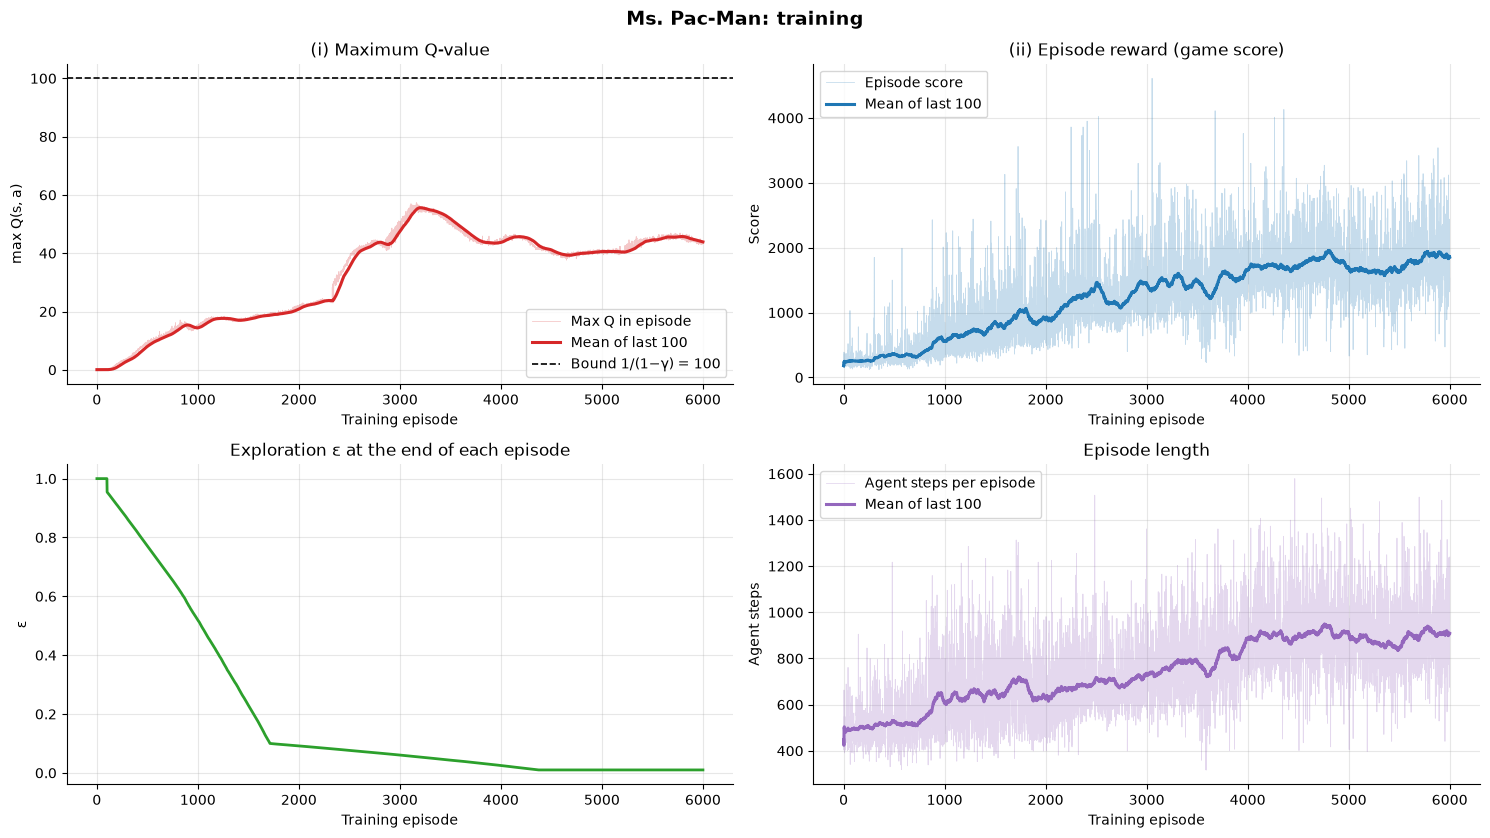

Mean score: first 500 episodes 296, last 500 episodes 1848, best MA100 1958


In [ ]:
episodes = np.arange(1, len(LOG["score"]) + 1)
fig, axes = plt.subplots(2, 2, figsize=(15, 8.5))
ax = axes[0, 0]
ax.plot(
    episodes,
    LOG["max_q"],
    color=COLORS[3],
    alpha=0.25,
    lw=0.6,
    label="Max Q in episode",
)
ax.plot(
    episodes,
    trailing_mean(LOG["max_q"]),
    color=COLORS[3],
    lw=2.2,
    label=f"Mean of last {WINDOW}",
)
ax.axhline(
    Q_BOUND, color="black", ls="--", lw=1.2, label=f"Bound 1/(1−γ) = {Q_BOUND:.0f}"
)
ax.set(title="(i) Maximum Q-value", xlabel="Training episode", ylabel="max Q(s, a)")
ax.legend(loc="lower right")

ax = axes[0, 1]
ax.plot(
    episodes, LOG["score"], color=COLORS[0], alpha=0.25, lw=0.6, label="Episode score"
)
ax.plot(
    episodes,
    trailing_mean(LOG["score"]),
    color=COLORS[0],
    lw=2.2,
    label=f"Mean of last {WINDOW}",
)
ax.set(
    title="(ii) Episode reward (game score)", xlabel="Training episode", ylabel="Score"
)
ax.legend(loc="upper left")

ax = axes[1, 0]
ax.plot(episodes, LOG["eps"], color=COLORS[2], lw=2)
ax.set(
    title="Exploration ε at the end of each episode",
    xlabel="Training episode",
    ylabel="ε",
)

ax = axes[1, 1]
ax.plot(
    episodes,
    LOG["length"],
    color=COLORS[4],
    alpha=0.25,
    lw=0.6,
    label="Agent steps per episode",
)
ax.plot(
    episodes,
    trailing_mean(LOG["length"]),
    color=COLORS[4],
    lw=2.2,
    label=f"Mean of last {WINDOW}",
)
ax.set(title="Episode length", xlabel="Training episode", ylabel="Agent steps")
ax.legend(loc="upper left")
fig.suptitle("Ms. Pac-Man: training", fontsize=14, fontweight="bold")
fig.tight_layout()
save_figure(fig, "training")
plt.show()

first, last = LOG["score"][:500].mean(), LOG["score"][-500:].mean()
print(
    f"Mean score: first 500 episodes {first:.0f}, last 500 episodes {last:.0f}, best MA100 {trailing_mean(LOG['score']).max():.0f}"
)

## 4. Model Selection and Evaluation

As in part (a), the reported network is chosen on **validation** games (seeds 10,000+), separate from the test games (seeds 0–499): every snapshot (every 500 episodes) plays 30 greedy validation games, and the one with the highest mean is evaluated on the 500 test games for plot (iii). The final weights are evaluated as well, and the uniformly random policy is the reference.

Validation ep 0:   0%|          | 0/30 [00:00<?, ?it/s]

Validation ep 500:   0%|          | 0/30 [00:00<?, ?it/s]

Validation ep 1000:   0%|          | 0/30 [00:00<?, ?it/s]

Validation ep 1500:   0%|          | 0/30 [00:00<?, ?it/s]

Validation ep 2000:   0%|          | 0/30 [00:00<?, ?it/s]

Validation ep 2500:   0%|          | 0/30 [00:00<?, ?it/s]

... (4 outputs left out)

Validation ep 5000:   0%|          | 0/30 [00:00<?, ?it/s]

Validation ep 5500:   0%|          | 0/30 [00:00<?, ?it/s]

Validation ep 6000:   0%|          | 0/30 [00:00<?, ?it/s]

Best snapshot on validation: episode 4000 (mean 1857); final: episode 6000 (mean 1835)


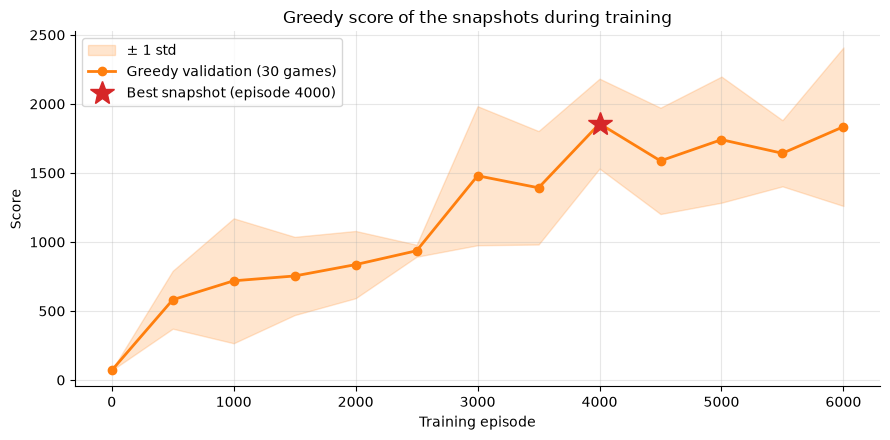

In [ ]:
SNAPSHOTS = snapshot_episodes(RUN_DIR)
VAL = {
    e: cached(
        f"val_ep{e:05d}",
        lambda e=e: evaluate(
            load_snapshot(RUN_DIR, e), n=N_VAL, seed=VAL_SEED, desc=f"Validation ep {e}"
        ),
    )
    for e in SNAPSHOTS
}
BEST_EP = max(SNAPSHOTS, key=lambda e: (VAL[e]["score"].mean(), e))
FINAL_EP = SNAPSHOTS[-1]
MODEL = load_snapshot(RUN_DIR, BEST_EP)
print(
    f"Best snapshot on validation: episode {BEST_EP} (mean {VAL[BEST_EP]['score'].mean():.0f}); final: episode {FINAL_EP} (mean {VAL[FINAL_EP]['score'].mean():.0f})"
)

fig, ax = plt.subplots(figsize=(9, 4.5))
means = np.array([VAL[e]["score"].mean() for e in SNAPSHOTS])
stds = np.array([VAL[e]["score"].std() for e in SNAPSHOTS])
ax.fill_between(
    SNAPSHOTS, means - stds, means + stds, color=COLORS[1], alpha=0.2, label="± 1 std"
)
ax.plot(
    SNAPSHOTS,
    means,
    "o-",
    color=COLORS[1],
    lw=2,
    label=f"Greedy validation ({N_VAL} games)",
)
ax.plot(
    BEST_EP,
    VAL[BEST_EP]["score"].mean(),
    "*",
    color=COLORS[3],
    ms=18,
    label=f"Best snapshot (episode {BEST_EP})",
)
ax.set(
    title="Greedy score of the snapshots during training",
    xlabel="Training episode",
    ylabel="Score",
)
ax.legend(loc="upper left")
fig.tight_layout()
save_figure(fig, "snapshots")
plt.show()

Test (best snapshot):   0%|          | 0/500 [00:00<?, ?it/s]

Test (final):   0%|          | 0/500 [00:00<?, ?it/s]

Test (random policy):   0%|          | 0/500 [00:00<?, ?it/s]

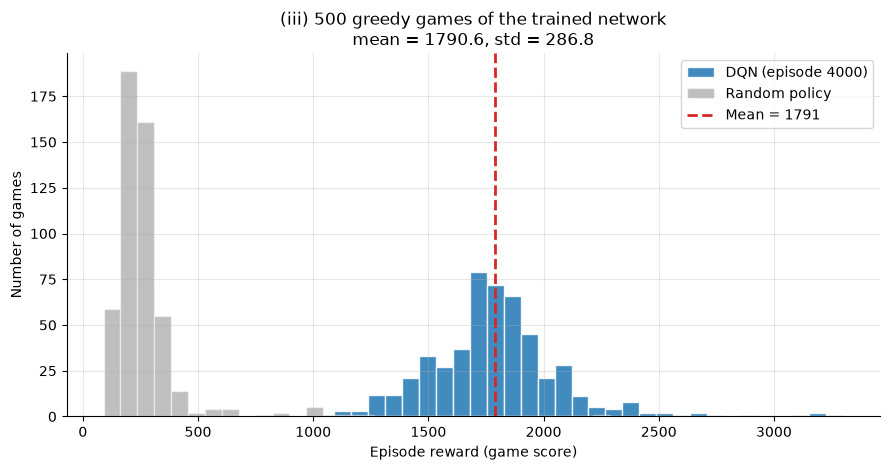

Network                             Mean ± std   Median     Max  Mean length
Best snapshot (ep 4000)         1790.6 ± 286.8      1780    3300          924
Final weights (ep 6000)         1842.7 ± 624.7      1715    4740          902
Random policy                    266.2 ± 164.6       240    2290          499


In [ ]:
EVAL = cached(
    f"eval_ep{BEST_EP:05d}", lambda: evaluate(MODEL, desc="Test (best snapshot)")
)
EVAL_FINAL = (
    EVAL
    if FINAL_EP == BEST_EP
    else cached(
        f"eval_ep{FINAL_EP:05d}",
        lambda: evaluate(load_snapshot(RUN_DIR, FINAL_EP), desc="Test (final)"),
    )
)
EVAL_RANDOM = cached("eval_random", lambda: evaluate(None, desc="Test (random policy)"))

scores = EVAL["score"]
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.hist(
    scores,
    bins=30,
    color=COLORS[0],
    alpha=0.85,
    edgecolor="white",
    label=f"DQN (episode {BEST_EP})",
)
ax.hist(
    EVAL_RANDOM["score"],
    bins=30,
    color="gray",
    alpha=0.5,
    edgecolor="white",
    label="Random policy",
)
ax.axvline(
    scores.mean(), color=COLORS[3], ls="--", lw=2, label=f"Mean = {scores.mean():.0f}"
)
ax.set(
    title=f"(iii) {len(scores)} greedy games of the trained network\nmean = {scores.mean():.1f}, std = {scores.std():.1f}",
    xlabel="Episode reward (game score)",
    ylabel="Number of games",
)
ax.legend()
fig.tight_layout()
save_figure(fig, "histogram")
plt.show()

print(f"{'Network':<28}{'Mean ± std':>18}{'Median':>9}{'Max':>8}{'Mean length':>13}")
for label, ev in (
    (f"Best snapshot (ep {BEST_EP})", EVAL),
    (f"Final weights (ep {FINAL_EP})", EVAL_FINAL),
    ("Random policy", EVAL_RANDOM),
):
    print(
        f"{label:<28}{ev['score'].mean():>10.1f} ± {ev['score'].std():<6.1f}{np.median(ev['score']):>9.0f}{ev['score'].max():>8.0f}{ev['length'].mean():>13.0f}"
    )

## 5. Non-Standard Plot: Where Does Ms. Pac-Man Go?

Ms. Pac-Man's position is read from her colour in the raw frame. The heatmaps show where she spends her time (log scale) over 10 greedy games, for the random policy and for snapshots across training, drawn over the maze. A good agent should leave the start area and clear the whole maze. The second figure follows one greedy game of the reported network: $\max_a Q$ at every step with the events that change it.

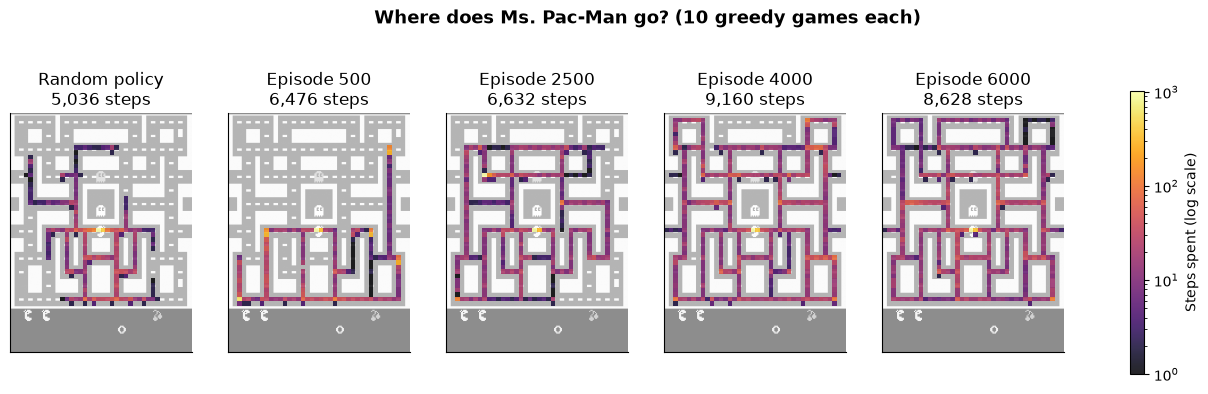

In [ ]:
HEAT_GAMES = 10
heat_eps = [e for e in SNAPSHOTS if e > 0]
heat_eps = (
    sorted({heat_eps[int(round(i))] for i in np.linspace(0, len(heat_eps) - 1, 4)})
    if heat_eps
    else []
)


def positions(net, n: int = HEAT_GAMES) -> np.ndarray:
    env = make_env()
    rng = np.random.default_rng(VAL_SEED)
    pos = np.concatenate(
        [
            rollout(net, VAL_SEED + i, env, record=True, rng=rng)["position"]
            for i in range(n)
        ]
    )
    env.close()
    return pos[~np.isnan(pos).any(axis=1)]


HEAT = {"Random policy": cached("heat_random", lambda: positions(None))}
for e in heat_eps:
    HEAT[f"Episode {e}"] = cached(
        f"heat_ep{e:05d}", lambda e=e: positions(load_snapshot(RUN_DIR, e))
    )

env = make_env()
maze, _ = env.reset(seed=EVAL_SEED)
env.close()
fig, axes = plt.subplots(1, len(HEAT), figsize=(3.4 * len(HEAT), 4.6))
bins = [np.arange(0, 211, 4), np.arange(0, 161, 4)]
for ax, (label, pos) in zip(np.atleast_1d(axes), HEAT.items()):
    ax.imshow(maze.mean(axis=2), cmap="gray", alpha=0.45, extent=(0, 160, 210, 0))
    h, _, _ = np.histogram2d(pos[:, 0], pos[:, 1], bins=bins)
    h = np.where(h > 0, h, np.nan)
    im = ax.imshow(
        h,
        cmap="inferno",
        norm=LogNorm(vmin=1, vmax=np.nanmax(h)),
        extent=(0, 160, 210, 0),
        alpha=0.85,
    )
    ax.set(title=f"{label}\n{len(pos):,} steps", xticks=[], yticks=[])
    ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.8, label="Steps spent (log scale)")
fig.suptitle(
    f"Where does Ms. Pac-Man go? ({HEAT_GAMES} greedy games each)",
    fontsize=13,
    fontweight="bold",
)
save_figure(fig, "heatmap")
plt.show()

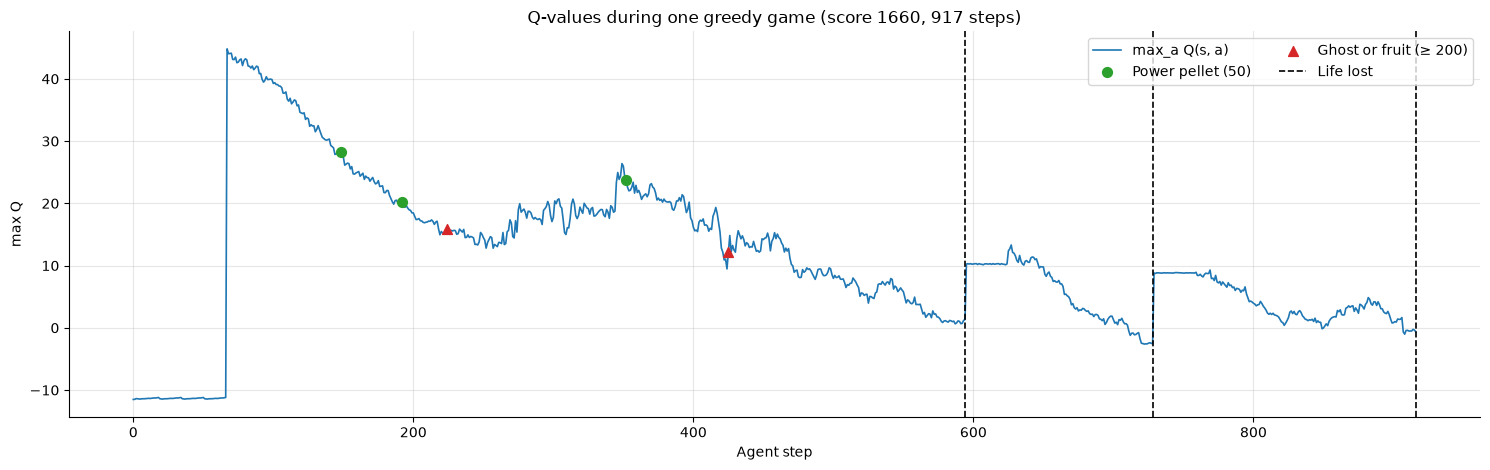

In [ ]:
env = make_env()
GAME = rollout(MODEL, EVAL_SEED, env, record=True)
env.close()
q_max = GAME["q"].max(axis=1)
t = np.arange(len(q_max))
fig, ax = plt.subplots(figsize=(15, 4.8))
ax.plot(t, q_max, color=COLORS[0], lw=1.2, label="max_a Q(s, a)")
for mask, marker, color, label in (
    (GAME["reward"] == 50, "o", COLORS[2], "Power pellet (50)"),
    (GAME["reward"] >= 200, "^", COLORS[3], "Ghost or fruit (≥ 200)"),
):
    ax.scatter(
        t[mask], q_max[mask], marker=marker, color=color, s=50, zorder=3, label=label
    )
for i, step in enumerate(np.flatnonzero(GAME["life_lost"])):
    ax.axvline(
        step, color="black", ls="--", lw=1.2, label="Life lost" if i == 0 else None
    )
ax.set(
    title=f"Q-values during one greedy game (score {GAME['score']:.0f}, {GAME['length']} steps)",
    xlabel="Agent step",
    ylabel="max Q",
)
ax.legend(loc="upper right", ncols=2)
fig.tight_layout()
save_figure(fig, "q_trace")
plt.show()

## 6. Edge Cases

| Edge case | Handling | Checked in |
|---|---|---|
| **Sticky actions** (v5: with 25 % probability the previous action is repeated) | Kept, as v5 prescribes. Even the greedy policy is therefore stochastic, so the evaluation std is not 0. | Test 9 (without sticky actions) |
| **Flickering sprites** (the ghosts are not drawn in every frame, see the stack in Section 1) | 4 stacked frames, so a ghost is visible in at least one of them | Preprocessing figure |
| **Life loss vs. game over** | A lost life is terminal for the TD target (no bootstrap through a death), but the game continues and the episode is the full game. | Test 3 |
| **Time limit** (108,000 frames) | A truncated game is not terminal. Its last step has no stored $s'$, so it is excluded from sampling instead of being treated as terminal. | Test 2 |
| **Frame stack at the start of a game** | Filled with the first frame; in the buffer, stacks never reach back into the previous game but repeat the first frame, exactly like the online stack. | Test 2 |
| **Buffer wrap-around** | Logical indices; a sample needs all 4 stack frames still stored and $s'$ already stored. | Test 2 |
| **Reward scale** (10 for a dot, up to 1,600 for a ghost) | The learning reward is clipped to $\{0, 1\}$, the reported score is the raw score. Q is bounded by $1/(1-\gamma) = 100$. | Test 6 |
| **int8 arithmetic of the preprocessing** | `img.sum` gives unsigned integers, so `img // 3 - 128` wraps around; the cast to int8 still gives the right value. | Test 1 |
| **Overestimation** | Double DQN, slow Polyak target network ($\tau = 0.001$), targets without gradients. | Test 6 (Q bound) |
| **Replay warm-up** | 50,000 random transitions before the first update. | Code |
| **Crash during the overnight run** | Atomic checkpoints every 250 episodes (incl. the replay buffer and all random-generator states); episodes seeded individually; deterministic GPU algorithms. | Test 10 (exact resume) |
| **Model selection on the test set** | Snapshots are compared on validation seeds (10,000+); the test uses seeds 0–499. | Section 4 |
| **Memory** | Frames stored once as int8 (7 GB for 1M transitions instead of 28 GB for stacked states); the full buffer is loaded without a copy. | Code |

## 7. Validation Tests

Every test prints `[PASS]` or `[FAIL]` with the measured numbers; the summary at the end lists all of them.

### Test 1: Preprocessing
**What:** The assignment's function on a real frame must give an 88×80 int8 frame equal to the same computation in signed arithmetic, and every pixel of Ms. Pac-Man (colour (210, 164, 74)) must become the darkest value, $0 // 3 - 128 = -128$.

In [ ]:
env = make_env()
obs, _ = env.reset(seed=EVAL_SEED)
env.close()
frame = preprocess(obs)
crop = obs[1:176:2, ::2].astype(np.int64)
reference = (
    np.where(crop.sum(axis=2) == MSPACMAN_COLOR, 0, crop.sum(axis=2)) // 3 - 128
).astype(np.int8)
pac_pixels = (crop == PACMAN_RGB).all(axis=2)
check(
    "T1a frame is 88×80 int8",
    frame.shape == FRAME_SHAPE and frame.dtype == np.int8,
    f"{frame.shape}, {frame.dtype}",
)
check(
    "T1b equals signed reference computation",
    np.array_equal(frame, reference),
    f"range [{frame.min()}, {frame.max()}]",
)
check(
    "T1c Ms. Pac-Man's pixels become −128",
    pac_pixels.any() and (frame[pac_pixels] == -128).all(),
    f"{pac_pixels.sum()} pixels",
)

[PASS] T1a frame is 88×80 int8: (88, 80), int8
[PASS] T1b equals signed reference computation: range [-128, 27]
[PASS] T1c Ms. Pac-Man's pixels become −128: 10 pixels


### Test 2: Replay buffer
**What:** A buffer of 64 frames is filled with 400 synthetic steps (games of random length, with lost lives and two truncated games). Each frame encodes its game and its step, so every sampled stack can be compared with the stack the agent actually saw. **Criteria:** (a) the stacks of $s$ equal the online stacks, (b) those of $s'$ equal the online stack of the next step, (c) no stack mixes two games, (d) the buffer wrapped around, (e) the last step of a truncated game is never sampled.

In [ ]:
def synthetic_buffer(size: int = 64, total: int = 400, seed: int = 0):
    rng = np.random.default_rng(seed)
    buffer, online, game = ReplayBuffer(size), {}, 0
    truncated_games = {3, 7}
    while buffer.count < total:
        length = int(rng.integers(1, 30))
        stack = FrameStack()
        for step in range(length):
            frame = np.zeros(FRAME_SHAPE, dtype=np.int8)
            frame[0, 0], frame[0, 1] = game % 100, step % 100
            s = stack.reset(frame) if step == 0 else stack.push(frame)
            online[buffer.count] = s.copy()
            ended = step == length - 1
            life_lost = bool(rng.random() < 0.1)
            terminal = (ended and game not in truncated_games) or life_lost
            buffer.add(
                frame, int(rng.integers(N_ACTIONS)), 1.0, terminal, ended, step == 0
            )
        game += 1
    return buffer, online


buffer, online_stacks = synthetic_buffer()
lo, hi = buffer.valid_range()
ts = np.arange(lo, hi + 1)
ok_s = ok_next = ok_games = True
for t in ts:
    states, _, _, terminal, next_states = buffer.batch(np.array([t]))
    ok_s &= np.array_equal(states[0], online_stacks[t])
    if not buffer.ended[t % buffer.size]:
        ok_next &= np.array_equal(next_states[0], online_stacks[t + 1])
    ok_games &= len(set(states[0][:, 0, 0].tolist())) == 1
sampled = buffer.sample_indices(5_000, np.random.default_rng(1))
truncated_last = (
    buffer.ended[sampled % buffer.size] & ~buffer.terminal[sampled % buffer.size]
)
check("T2a stacks of s equal the online stacks", ok_s, f"{len(ts)} indices")
check("T2b stacks of s' equal the next online stack", ok_next)
check("T2c no stack mixes two games", ok_games)
check(
    "T2d buffer wrapped around",
    buffer.count > 3 * buffer.size,
    f"{buffer.count} frames added to a buffer of {buffer.size}",
)
check(
    "T2e truncated last steps are never sampled",
    not truncated_last.any(),
    f"{len(sampled)} samples",
)

[PASS] T2a stacks of s equal the online stacks: 60 indices
[PASS] T2b stacks of s' equal the next online stack
[PASS] T2c no stack mixes two games
[PASS] T2d buffer wrapped around: 421 frames added to a buffer of 64
[PASS] T2e truncated last steps are never sampled: 5000 samples


### Test 3: Life loss
**What:** One game with random actions through the same `env_step` the training uses. **Criteria:** exactly 3 lives are lost, the last one together with the end of the game, and the game is not reset after a lost life (the frame counter keeps increasing).

In [ ]:
env = make_env()
obs, info = env.reset(seed=EVAL_SEED)
lives, rng, events, frame_numbers = info["lives"], np.random.default_rng(0), [], [0]
while True:
    obs, reward, terminated, truncated, lives, life_lost = env_step(
        env, int(rng.integers(N_ACTIONS)), lives
    )
    frame_numbers.append(env.unwrapped.ale.getEpisodeFrameNumber())
    if life_lost:
        events.append((len(frame_numbers) - 1, lives, terminated))
    if terminated or truncated:
        break
env.close()
print(
    "Lives lost at steps:",
    [
        (step, f"{left} left", "game over" if over else "game goes on")
        for step, left, over in events
    ],
)
check(
    "T3a three lives are lost per game",
    len(events) == 3,
    f"{len(events)} TD-terminal steps",
)
check(
    "T3b only the last life loss ends the game",
    [over for *_, over in events] == [False, False, True],
)
check(
    "T3c the game is not reset after a lost life",
    np.all(np.diff(frame_numbers) > 0),
    f"frame counter 0 → {frame_numbers[-1]}",
)

Lives lost at steps: [(189, '2 left', 'game goes on'), (343, '1 left', 'game goes on'), (535, '0 left', 'game over')]
[PASS] T3a three lives are lost per game: 3 TD-terminal steps
[PASS] T3b only the last life loss ends the game
[PASS] T3c the game is not reset after a lost life: frame counter 0 → 2137


### Test 4: Does the agent learn?
**Criteria:** (a) the mean score of the last 500 training episodes is more than twice that of the first 500 (training is $\epsilon$-greedy, so this includes exploration), (b) the greedy test score of the reported network is more than twice the random policy's.

In [ ]:
check(
    "T4a training score improves (last 500 > 2 × first 500)",
    last > 2 * first,
    f"{first:.0f} → {last:.0f}",
)
check(
    "T4b trained network beats the random policy (> 2×)",
    EVAL["score"].mean() > 2 * EVAL_RANDOM["score"].mean(),
    f"{EVAL['score'].mean():.0f} vs. {EVAL_RANDOM['score'].mean():.0f}",
)

[PASS] T4a training score improves (last 500 > 2 × first 500): 296 → 1848
[PASS] T4b trained network beats the random policy (> 2×): 1791 vs. 266


### Test 5: Progress over training
**What:** The greedy validation score of the snapshots (Section 4) must rise with training. **Criteria:** (a) Spearman rank correlation between training episode and validation mean > 0.7, (b) the best snapshot scores more than 3× the untrained network (episode 0).

In [ ]:
ranks = lambda x: np.argsort(np.argsort(x))
spearman = np.corrcoef(ranks(np.array(SNAPSHOTS)), ranks(means))[0, 1]
check(
    "T5a validation score rises with training",
    spearman > 0.7,
    f"Spearman ρ = {spearman:.2f} over {len(SNAPSHOTS)} snapshots",
)
check(
    "T5b best snapshot > 3 × untrained network",
    means.max() > 3 * means[0],
    f"{means[0]:.0f} → {means.max():.0f}",
)

[PASS] T5a validation score rises with training: Spearman ρ = 0.93 over 13 snapshots
[PASS] T5b best snapshot > 3 × untrained network: 70 → 1857


### Test 6: Q-values vs. actual returns
**What:** With rewards clipped to $\{0, 1\}$, Q is bounded by $1/(1-\gamma) = 100$. Along 10 greedy test games of the reported network, the predicted $Q(s_t, a_t)$ is compared with the actual discounted return $G_t$ of the clipped rewards, cut off at every lost life (exactly the quantity the network learns, since a lost life is terminal for the target). Unlike Test 1 of part (a), these roll-outs are greedy, so $Q$ and $G$ refer to the same policy. **Criteria:** (a) max Q during training stays below the bound, (b) correlation of Q and $G$ > 0.5, (c) Q in the last 10 steps before a lost life is below 80 % of the mean Q (the network sees death coming).

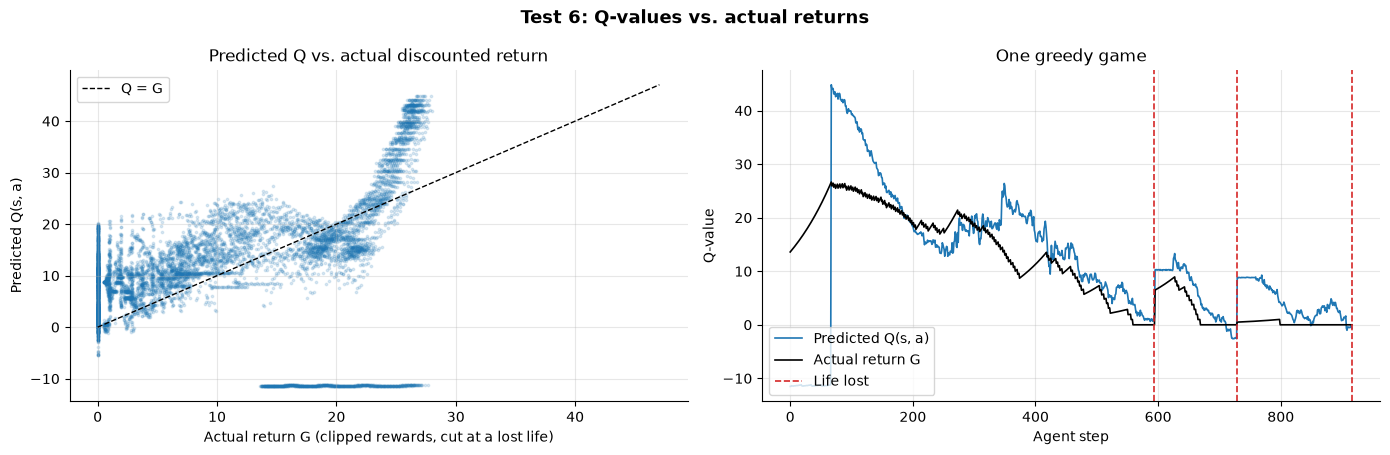

Mean Q 12.45, mean G 10.46 (overestimation +1.99)
[PASS] T6a max Q stays below the bound of 100: max Q over training = 57.3
[FAIL] T6b Q correlates with the actual return: r = 0.46 over 8,910 steps
[PASS] T6c Q drops before a lost life: mean Q in the 10 steps before a lost life 4.5 vs. overall 12.5


In [ ]:
def returns_to_go(game: dict, gamma: float = GAMMA) -> np.ndarray:
    r = np.sign(game["reward"])
    g, out = 0.0, np.zeros(len(r))
    for t in range(len(r) - 1, -1, -1):
        g = r[t] + (0.0 if game["life_lost"][t] else gamma * g)
        out[t] = g
    return out


def calibration_games(n: int = 10) -> list[dict]:
    env = make_env()
    games = [rollout(MODEL, EVAL_SEED + i, env, record=True) for i in range(n)]
    env.close()
    return [
        {k: g[k] for k in ("q", "action", "reward", "life_lost", "score")}
        for g in games
    ]


GAMES = cached(f"calibration_ep{BEST_EP:05d}", calibration_games)
q_taken = np.concatenate(
    [g["q"][np.arange(len(g["action"])), g["action"]] for g in GAMES]
)
g_true = np.concatenate([returns_to_go(g) for g in GAMES])
before_death = np.concatenate(
    [
        np.isin(
            np.arange(len(g["action"])),
            [s - k for s in np.flatnonzero(g["life_lost"]) for k in range(10)],
        )
        for g in GAMES
    ]
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6))
ax1.scatter(g_true, q_taken, s=3, alpha=0.15, color=COLORS[0])
lim = max(g_true.max(), q_taken.max()) * 1.05
ax1.plot([0, lim], [0, lim], color="black", ls="--", lw=1, label="Q = G")
ax1.set(
    title="Predicted Q vs. actual discounted return",
    xlabel="Actual return G (clipped rewards, cut at a lost life)",
    ylabel="Predicted Q(s, a)",
)
ax1.legend()
game = GAMES[0]
ax2.plot(
    game["q"][np.arange(len(game["action"])), game["action"]],
    color=COLORS[0],
    lw=1.2,
    label="Predicted Q(s, a)",
)
ax2.plot(returns_to_go(game), color="black", lw=1.2, label="Actual return G")
for i, step in enumerate(np.flatnonzero(game["life_lost"])):
    ax2.axvline(
        step, color=COLORS[3], ls="--", lw=1.2, label="Life lost" if i == 0 else None
    )
ax2.set(title="One greedy game", xlabel="Agent step", ylabel="Q-value")
ax2.legend(loc="lower left")
fig.suptitle("Test 6: Q-values vs. actual returns", fontsize=13, fontweight="bold")
fig.tight_layout()
save_figure(fig, "test_q_calibration")
plt.show()

corr = np.corrcoef(q_taken, g_true)[0, 1]
print(
    f"Mean Q {q_taken.mean():.2f}, mean G {g_true.mean():.2f} (overestimation {q_taken.mean() - g_true.mean():+.2f})"
)
check(
    "T6a max Q stays below the bound of 100",
    LOG["max_q"].max() < Q_BOUND,
    f"max Q over training = {LOG['max_q'].max():.1f}",
)
check(
    "T6b Q correlates with the actual return",
    corr > 0.5,
    f"r = {corr:.2f} over {len(q_taken):,} steps",
)
check(
    "T6c Q drops before a lost life",
    q_taken[before_death].mean() < 0.8 * q_taken.mean(),
    f"mean Q in the 10 steps before a lost life {q_taken[before_death].mean():.1f} vs. overall {q_taken.mean():.1f}",
)

### Test 7: $\gamma = 0$ sanity run
**What:** With $\gamma = 0$, the target is only the clipped immediate reward, so a correct implementation must learn $Q(s, a) = P(\text{reward} \mid s, a) \in [0, 1]$, and on average Q must equal the reward rate. A short run (60 games, random actions throughout, so that the data matches the evaluation states) checks the target computation in isolation from bootstrapping. **Criteria:** (a) all Q-values within $[-0.1, 1.1]$, (b) the mean Q of the taken actions within 0.05 of the mean clipped reward on new random games.

In [ ]:
GAMMA0 = replace(
    MAIN,
    name="test_gamma0",
    episodes=60,
    gamma=0.0,
    buffer_size=50_000,
    learning_starts=2_000,
    eps_values=(1.0, 1.0, 1.0),
    checkpoint_every=60,
    snapshot_every=60,
)
train(GAMMA0, CHECKPOINTS / GAMMA0.name)
net0 = load_snapshot(CHECKPOINTS / GAMMA0.name, GAMMA0.episodes)
env = make_env()
games0 = [rollout(net0, VAL_SEED + i, env, eps=1.0, record=True) for i in range(5)]
env.close()
q0 = np.concatenate([g["q"] for g in games0])
q0_taken = np.concatenate([g["q"][np.arange(g["length"]), g["action"]] for g in games0])
r0 = np.concatenate([np.sign(g["reward"]) for g in games0])
check(
    "T7a γ = 0: all Q-values in [−0.1, 1.1]",
    q0.min() > -0.1 and q0.max() < 1.1,
    f"range [{q0.min():.3f}, {q0.max():.3f}]",
)
check(
    "T7b γ = 0: mean Q = reward rate",
    abs(q0_taken.mean() - r0.mean()) < 0.05,
    f"mean Q {q0_taken.mean():.3f}, reward rate {r0.mean():.3f}",
)

test_gamma0:   0%|          | 0/60 [00:00<?, ?it/s]

Checkpoint at episode 60: step 29,938, MA100 263, ε 1.000, saved in 0 s
[PASS] T7a γ = 0: all Q-values in [−0.1, 1.1]: range [-0.032, 0.343]
[PASS] T7b γ = 0: mean Q = reward rate: mean Q 0.053, reward rate 0.052


### Test 8: The first 10 steps
**What:** The first 10 steps of a greedy test game of the reported network (all inside the start delay, in which the game ignores every action), and the first 10 steps after it: action, the Q-values of all 9 actions, raw and clipped reward, and the TD target $y = r + \gamma (1 - \text{terminal}) \max_a Q(s', a)$ computed with the same network. **Criterion:** mean |TD error| over the whole game < 1 (the network is close to a fixed point of its own Bellman update; Q values are up to 100).

In [ ]:
game = GAME
q, a, rew, lost = game["q"], game["action"], game["reward"], game["life_lost"]
r_clip = np.sign(rew)
next_max = np.append(q[1:].max(axis=1), 0.0)
y = r_clip + GAMMA * (1 - lost) * next_max
td = y - q[np.arange(len(a)), a]
header = (
    "  t  action    "
    + " ".join(f"{name[:5]:>6}" for name in ACTION_NAMES)
    + "   raw r  r  y       TD err"
)
print(header)
for t in range(10):
    print(
        f"{t:>3}  {ACTION_NAMES[a[t]]:<9} "
        + " ".join(f"{v:6.2f}" for v in q[t])
        + f"  {rew[t]:6.0f}  {r_clip[t]:.0f}  {y[t]:6.2f}  {td[t]:+7.3f}"
    )
check(
    "T8 small TD error along a greedy game",
    np.abs(td[:-1]).mean() < 1.0,
    f"mean |TD error| = {np.abs(td[:-1]).mean():.3f} over {len(td)} steps, action gap median {np.median(q.max(axis=1) - np.sort(q, axis=1)[:, -2]):.3f}",
)

  t  action      NOOP     UP  RIGHT   LEFT   DOWN  UPRIG  UPLEF  DOWNR  DOWNL   raw r  r  y       TD err
  0  UPRIGHT   -11.53 -11.52 -11.52 -11.53 -11.51 -11.51 -11.52 -11.52 -11.51       0  0  -11.38   +0.124
  1  UPRIGHT   -11.52 -11.51 -11.51 -11.52 -11.50 -11.50 -11.51 -11.51 -11.50       0  0  -11.26   +0.236
  2  UPRIGHT   -11.40 -11.39 -11.39 -11.40 -11.38 -11.38 -11.39 -11.39 -11.38       0  0  -11.28   +0.093
  3  UPRIGHT   -11.42 -11.41 -11.41 -11.42 -11.40 -11.40 -11.41 -11.41 -11.40       0  0  -11.31   +0.082
  4  UPRIGHT   -11.45 -11.44 -11.44 -11.45 -11.44 -11.43 -11.44 -11.44 -11.43       0  0  -11.34   +0.088
  5  UPRIGHT   -11.48 -11.47 -11.47 -11.47 -11.46 -11.45 -11.47 -11.47 -11.46       0  0  -11.29   +0.168
  6  UPRIGHT   -11.42 -11.41 -11.41 -11.42 -11.41 -11.40 -11.41 -11.41 -11.41       0  0  -11.29   +0.109
  7  UPRIGHT   -11.43 -11.42 -11.42 -11.43 -11.41 -11.41 -11.42 -11.42 -11.41       0  0  -11.28   +0.123
  8  UPRIGHT   -11.42 -11.41 -11.41 -11.42 -11.

In [ ]:
# The 10 steps right after the start delay, when Ms. Pac-Man can move: rewards, Q-values and TD targets interact
play = int(np.argmax(np.abs(q.max(axis=1) - q[0].max()) > 1))  # first step whose Q differs from the delay value
print(f"Play starts at step {play}")
print(header)
for t in range(play, play + 10):
    print(f"{t:>3}  {ACTION_NAMES[a[t]]:<9} " + " ".join(f"{v:6.2f}" for v in q[t]) + f"  {rew[t]:6.0f}  {r_clip[t]:.0f}  {y[t]:6.2f}  {td[t]:+7.3f}")

Play starts at step 67
  t  action      NOOP     UP  RIGHT   LEFT   DOWN  UPRIG  UPLEF  DOWNR  DOWNL   raw r  r  y       TD err
 67  UP         44.80  44.82  44.75  44.58  44.71  44.77  44.49  44.75  44.53      10  1   44.60   -0.224
 68  UP         44.01  44.04  43.80  43.72  43.98  43.85  43.60  43.82  43.67       0  0   43.64   -0.396
 69  UP         44.01  44.08  43.87  43.30  44.06  43.91  43.26  43.89  43.29       0  0   43.68   -0.399
 70  DOWN       43.96  44.09  43.89  43.13  44.12  43.91  43.12  43.96  43.18      10  1   43.69   -0.436
 71  DOWN       42.46  42.55  42.60  42.14  43.12  42.53  42.09  42.95  42.27       0  0   42.67   -0.448
 72  DOWN       42.87  42.45  42.89  42.82  43.10  42.87  42.78  43.02  42.87       0  0   43.06   -0.041
 73  UPRIGHT    43.49  42.31  43.41  43.39  43.40  43.49  43.40  43.43  43.38      10  1   43.17   -0.328
 74  DOWN       42.54  41.87  42.47  42.54  42.59  42.48  42.51  42.51  42.55       0  0   42.26   -0.328
 75  NOOP       42.69  4

### Test 9: Harder evaluation
**What:** The reported network on 100 test games each with 5 % random actions ($\epsilon = 0.05$) and without sticky actions (fully deterministic emulator). **Criterion:** both stay above twice the random policy.

In [ ]:
HARD = {
    "Greedy, sticky actions (standard)": EVAL,
    "ε = 0.05": cached(
        f"hard_eps_ep{BEST_EP:05d}",
        lambda: evaluate(MODEL, n=100, eps=0.05, desc="ε = 0.05"),
    ),
    "No sticky actions": cached(
        f"hard_nosticky_ep{BEST_EP:05d}",
        lambda: evaluate(MODEL, n=100, sticky=False, desc="No sticky actions"),
    ),
}
for label, ev in HARD.items():
    print(f"{label:<36}{ev['score'].mean():>9.1f} ± {ev['score'].std():.1f}")
random_mean = EVAL_RANDOM["score"].mean()
check(
    "T9 robust to random actions and without sticky actions (> 2 × random)",
    all(ev["score"].mean() > 2 * random_mean for ev in HARD.values()),
    f"random policy {random_mean:.0f}",
)

ε = 0.05:   0%|          | 0/100 [00:00<?, ?it/s]

No sticky actions:   0%|          | 0/100 [00:00<?, ?it/s]

Greedy, sticky actions (standard)      1790.6 ± 286.8
ε = 0.05                               1781.7 ± 420.0
No sticky actions                      1710.0 ± 0.0
[PASS] T9 robust to random actions and without sticky actions (> 2 × random): random policy 266


### Test 10: Exact resume after a crash
**What:** The crash recovery itself. A small configuration is trained for 6 games in one go, and a second time for 3 games, after which `train` returns (as if the kernel died) and is called again, resuming from the checkpoint. **Criteria:** identical scores, losses and Q-values per episode, and identical final weights.

In [ ]:
RESUME = replace(
    MAIN,
    name="test_resume",
    episodes=6,
    buffer_size=20_000,
    learning_starts=1_000,
    eps_steps=(0, 2_000, 4_000),
    checkpoint_every=3,
    snapshot_every=6,
)
straight_dir, resumed_dir = (
    CHECKPOINTS / "test_resume_straight",
    CHECKPOINTS / "test_resume_crash",
)
for d in (straight_dir, resumed_dir):
    shutil.rmtree(d, ignore_errors=True)
log_straight = train(RESUME, straight_dir, progress=False)
train(RESUME, resumed_dir, stop_at=3, progress=False)  # "crash" after 3 games
log_resumed = train(RESUME, resumed_dir, progress=False)
same_log = all(
    np.allclose(log_straight[k], log_resumed[k], equal_nan=True)
    for k in ("score", "clipped", "length", "max_q", "loss", "steps")
)
w1 = load_snapshot(straight_dir, RESUME.episodes).state_dict()
w2 = load_snapshot(resumed_dir, RESUME.episodes).state_dict()
same_weights = all(torch.equal(w1[k], w2[k]) for k in w1)
print(
    "Scores straight:",
    log_straight["score"],
    "\nScores resumed: ",
    log_resumed["score"],
)
check("T10a resumed run has the same log", same_log)
check("T10b resumed run has identical weights", same_weights)
for d in (straight_dir, resumed_dir):
    shutil.rmtree(d, ignore_errors=True)

Resumed checkpoints\b\test_resume_crash at episode 3 (step 1,335) from checkpoint/
Scores straight: [180. 190. 300. 560. 670. 570.] 
Scores resumed:  [180. 190. 300. 560. 670. 570.]
[PASS] T10a resumed run has the same log
[PASS] T10b resumed run has identical weights


### Summary of all checks

In [25]:
n_pass = sum(passed for _, passed in CHECKS)
print(f"{n_pass}/{len(CHECKS)} checks passed")
for name, passed in CHECKS:
    print(f"  [{'PASS' if passed else 'FAIL'}] {name}")

23/24 checks passed
  [PASS] T1a frame is 88×80 int8
  [PASS] T1b equals signed reference computation
  [PASS] T1c Ms. Pac-Man's pixels become −128
  [PASS] T2a stacks of s equal the online stacks
  [PASS] T2b stacks of s' equal the next online stack
  [PASS] T2c no stack mixes two games
  [PASS] T2d buffer wrapped around
  [PASS] T2e truncated last steps are never sampled
  [PASS] T3a three lives are lost per game
  [PASS] T3b only the last life loss ends the game
  [PASS] T3c the game is not reset after a lost life
  [PASS] T4a training score improves (last 500 > 2 × first 500)
  [PASS] T4b trained network beats the random policy (> 2×)
  [PASS] T5a validation score rises with training
  [PASS] T5b best snapshot > 3 × untrained network
  [PASS] T6a max Q stays below the bound of 100
  [FAIL] T6b Q correlates with the actual return
  [PASS] T6c Q drops before a lost life
  [PASS] T7a γ = 0: all Q-values in [−0.1, 1.1]
  [PASS] T7b γ = 0: mean Q = reward rate
  [PASS] T8 small TD error

## Watch the Agent Play
Opens a game window and lets the selected network (`MODEL`, the best snapshot) play greedily in real time, with sticky actions as in training and evaluation. It needs the cells above up to *Model Selection* (for `MODEL`). Change `WATCH_SEED` for a different game, or set `WATCH_MODEL = load_snapshot(RUN_DIR, 500)` to compare an early snapshot. Interrupting the cell closes the window.

In [ ]:
WATCH_MODEL = MODEL
WATCH_SEED = 0
WATCH_GAMES = 1

env = make_env(render_mode="human")
try:
    for game in range(WATCH_GAMES):
        obs, info = env.reset(seed=WATCH_SEED + game)
        stack = FrameStack()
        s = stack.reset(preprocess(obs))
        lives, score, n = info["lives"], 0.0, 0
        while True:
            action = int(q_values(WATCH_MODEL, s).argmax())
            obs, reward, terminated, truncated, lives, life_lost = env_step(
                env, action, lives
            )
            score, n = score + reward, n + 1
            if life_lost:
                print(f"  life lost at step {n}, score so far {score:.0f}")
            if terminated or truncated:
                break
            s = stack.push(preprocess(obs))
        print(
            f"Game {game + 1} (seed {WATCH_SEED + game}): score {score:.0f} in {n} steps"
        )
finally:
    env.close()

  life lost at step 595, score so far 1540
  life lost at step 729, score so far 1650
  life lost at step 917, score so far 1660
Game 1 (seed 0): score 1660 in 917 steps


: 